In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Heart Disease Data Cleaning Project")
print("All libraries imported successfully!")

Heart Disease Data Cleaning Project
All libraries imported successfully!


In [2]:
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/heart-disease/processed.cleveland.data"
)

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(
    url,
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:

# 1. Inspect data types and non-null counts
print("DATASET INFORMATION")
df.info()

# 2. Check missing values in each column
print("\nMISSING VALUES")
print(df.isnull().sum())

# 3. Check duplicate records
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# 4. Summary statistics for numerical columns
print("\nSUMMARY STATISTICS")
display(df.describe().T)

# 5. Check distinct values in selected categorical columns
print("\nCATEGORICAL VALUE COUNTS")
for col in ["sex", "cp", "fbs", "restecg",
            "exang", "slope", "ca", "thal", "target"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).sort_index())


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

MISSING VALUES
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2



CATEGORICAL VALUE COUNTS

sex:
sex
0.0     97
1.0    206
Name: count, dtype: int64

cp:
cp
1.0     23
2.0     50
3.0     86
4.0    144
Name: count, dtype: int64

fbs:
fbs
0.0    258
1.0     45
Name: count, dtype: int64

restecg:
restecg
0.0    151
1.0      4
2.0    148
Name: count, dtype: int64

exang:
exang
0.0    204
1.0     99
Name: count, dtype: int64

slope:
slope
1.0    142
2.0    140
3.0     21
Name: count, dtype: int64

ca:
ca
0.0    176
1.0     65
2.0     38
3.0     20
NaN      4
Name: count, dtype: int64

thal:
thal
3.0    166
6.0     18
7.0    117
NaN      2
Name: count, dtype: int64

target:
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,age,48.0,61.0,13.0,28.50,80.50,0
1,trestbps,120.0,140.0,20.0,90.00,170.00,9
2,chol,211.0,275.0,64.0,115.00,371.00,5
3,thalach,133.5,166.0,32.5,84.75,214.75,1
4,oldpeak,0.0,1.6,1.6,-2.40,4.00,5


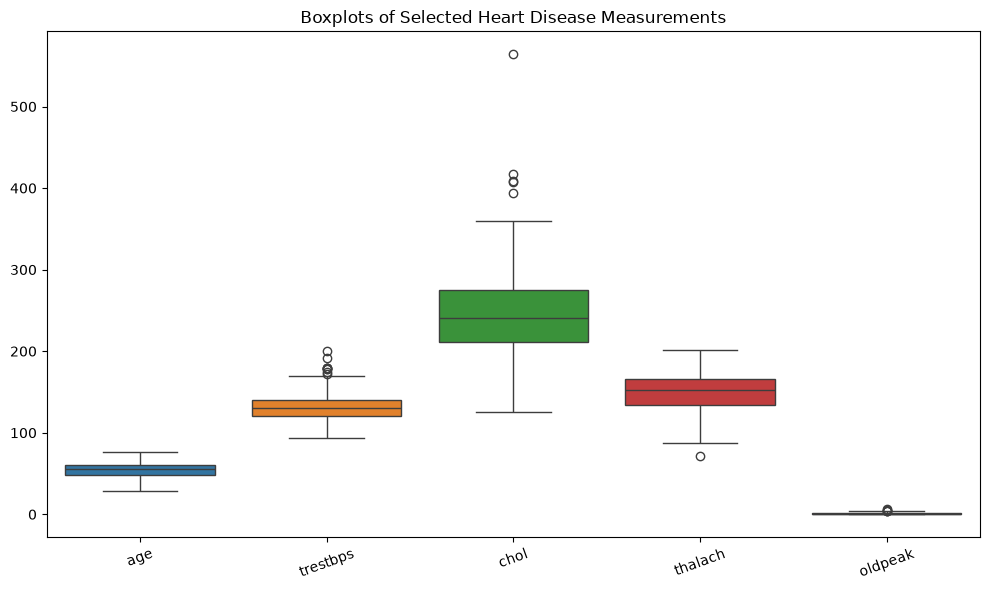

In [4]:

# Select continuous numerical measurements for outlier analysis
continuous_cols = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

# Calculate IQR-based outlier boundaries and counts
outlier_results = []

for col in continuous_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) | (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Column": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

# Visualise the distributions using boxplots
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[continuous_cols])
plt.title("Boxplots of Selected Heart Disease Measurements")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [5]:
# Create a copy so the original dataset remains unchanged
df_clean = df.copy()

# Check missing values before cleaning
print("Missing values before cleaning:")
print(df_clean.isnull().sum())

# Fill missing values using the mode
df_clean["ca"] = df_clean["ca"].fillna(df_clean["ca"].mode()[0])
df_clean["thal"] = df_clean["thal"].fillna(df_clean["thal"].mode()[0])

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)

Missing values before cleaning:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Missing values after cleaning:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Cleaned dataset shape: (303, 14)


In [6]:
# Check duplicate rows
print("Duplicate rows:", df_clean.duplicated().sum())

# Check valid categories
valid_categories = {
    "sex": [0, 1],
    "cp": [1, 2, 3, 4],
    "fbs": [0, 1],
    "restecg": [0, 1, 2],
    "exang": [0, 1],
    "slope": [1, 2, 3],
    "ca": [0, 1, 2, 3],
    "thal": [3, 6, 7],
    "target": [0, 1, 2, 3, 4]
}

for column, allowed_values in valid_categories.items():
    invalid = df_clean.loc[
        ~df_clean[column].isin(allowed_values), column
    ]
    print(f"{column}: {len(invalid)} invalid values")

print("\nRemaining missing values:", df_clean.isnull().sum().sum())

Duplicate rows: 0
sex: 0 invalid values
cp: 0 invalid values
fbs: 0 invalid values
restecg: 0 invalid values
exang: 0 invalid values
slope: 0 invalid values
ca: 0 invalid values
thal: 0 invalid values
target: 0 invalid values

Remaining missing values: 0


In [7]:
df_clean.to_csv("../data/heart_disease_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [8]:
# Compare the original and cleaned datasets

comparison = pd.DataFrame({
    "Metric": [
        "Number of rows",
        "Number of columns",
        "Missing values",
        "Duplicate rows"
    ],
    "Before Cleaning": [
        len(df),
        len(df.columns),
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ],
    "After Cleaning": [
        len(df_clean),
        len(df_clean.columns),
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum()
    ]
})

display(comparison)

,Metric,Before Cleaning,After Cleaning
0,Number of rows,303,303
1,Number of columns,14,14
2,Missing values,6,0
3,Duplicate rows,0,0


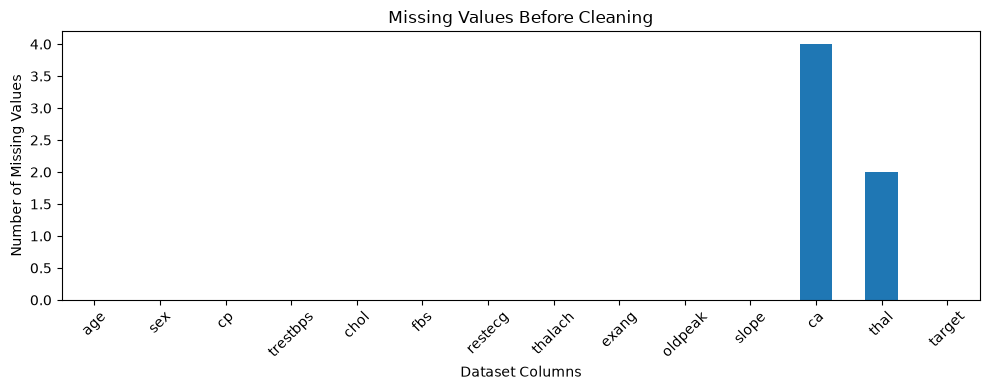

In [9]:
# Visualize missing values before cleaning
plt.figure(figsize=(10, 4))
df.isnull().sum().plot(kind="bar")
plt.title("Missing Values Before Cleaning")
plt.xlabel("Dataset Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

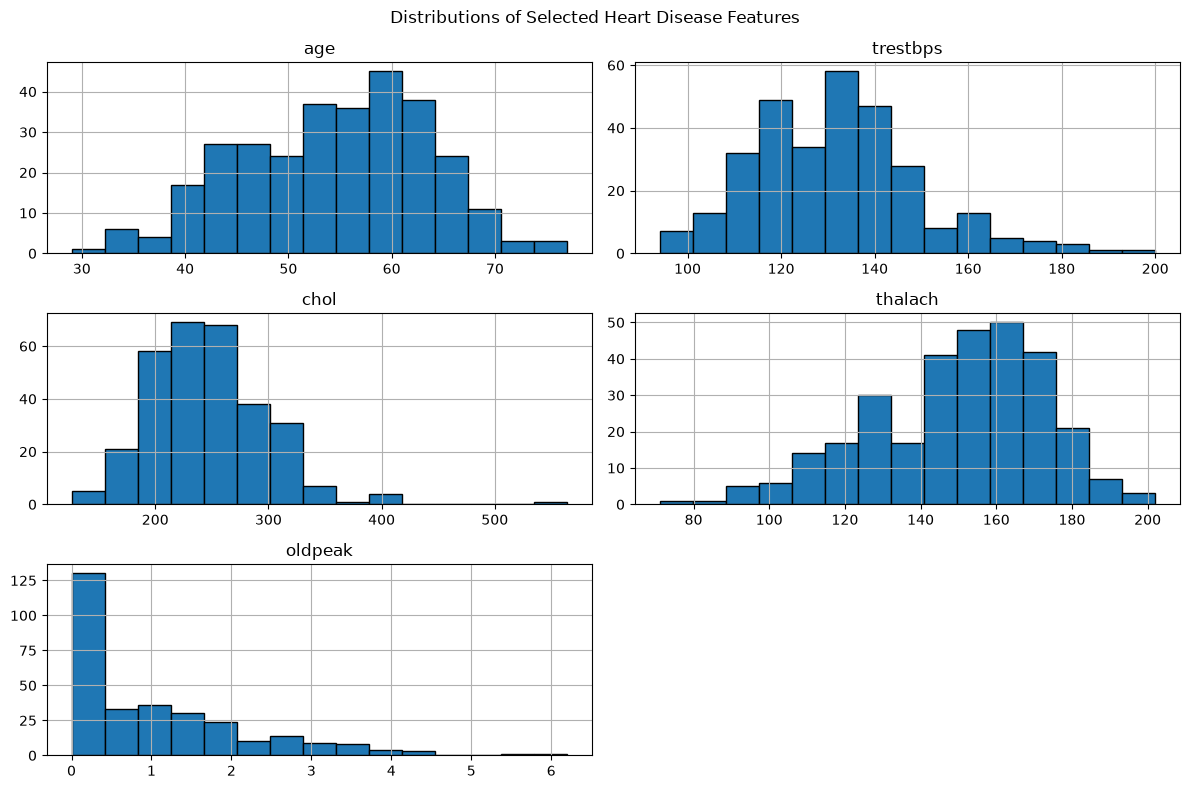

In [10]:
# Visualize selected numerical features after cleaning
continuous_cols = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

df_clean[continuous_cols].hist(
    figsize=(12, 8), bins=15, edgecolor="black"
)

plt.suptitle("Distributions of Selected Heart Disease Features")
plt.tight_layout()
plt.show()